Re_MR = 0.0
u_avg = 0.0
Determinant of A_visc_new is 1.0000000061344902
mu = 0.035
f = 0.0
Re_MR = 0.3250250733117498
u_avg = 0.0008143001090015729
Determinant of A_visc_new is 1.0000000263468982
mu = 0.15032080916910223
f = 49.22697143630363
Re_MR = 1.3238756730279937
u_avg = 0.002624577556398462
Determinant of A_visc_new is 1.0000000208484539
mu = 0.11894991097183291
f = 12.085727025563129
Re_MR = 3.4184062693231727
u_avg = 0.0057859227246761236
Determinant of A_visc_new is 1.0000000177995807
mu = 0.10155503909007164
f = 4.680543721085534
Re_MR = 7.006487718821703
u_avg = 0.01052210378546831
Determinant of A_visc_new is 1.0000000157928872
mu = 0.09010636855962587
f = 2.2835978085023685
Re_MR = 12.388394101568128
u_avg = 0.016918587276051153
Determinant of A_visc_new is 1.0000000143617118
mu = 0.08194136311152565
f = 1.2915314017960338
Re_MR = 19.72315191538813
u_avg = 0.02492668170347839
Determinant of A_visc_new is 1.000000013290526
mu = 0.07583035861611268
f = 0.8112293647911669
Re

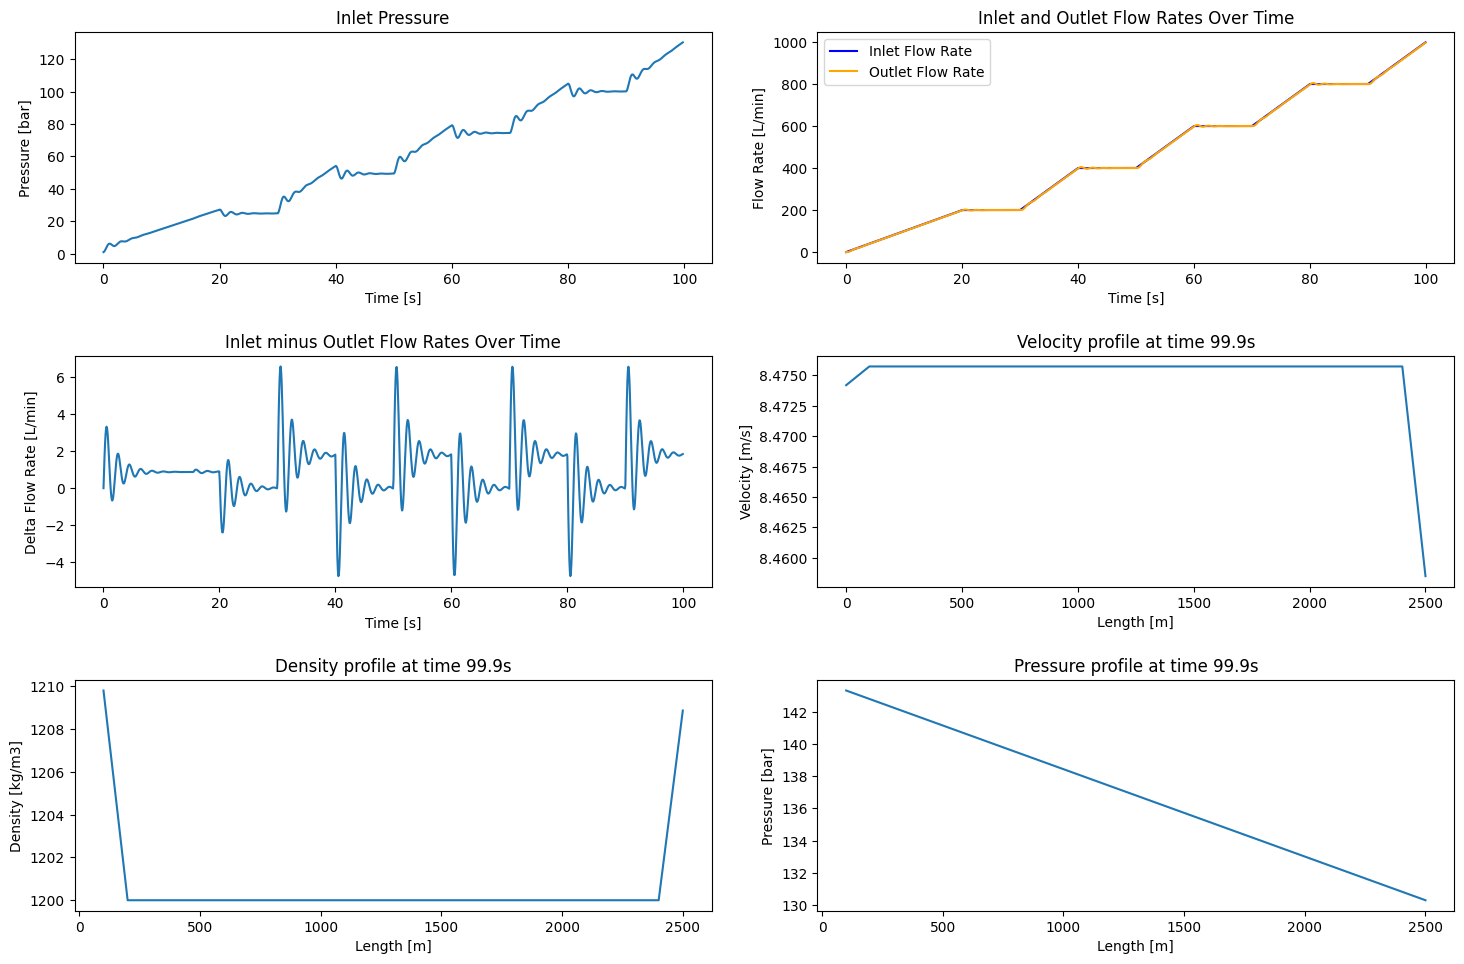

Simulation completed in 1146 steps
Max inlet pressure: 130.4 bar at time 99.92s
Maximum flow out: 996.5 L/min
Minimum flow out: 0.0 L/min


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve

# ======================
# Simulation Parameters
# ======================
dx = 100.0            # Spatial step [m]
L = 2500.0             # Pipe length [m]
N = int(L // dx)     # Number of spatial cells
T_max = 100.0         # Total simulation time [s]
cfl = 0.8            # CFL number

# Fluid Properties
rho_0 = 1200.0       # Reference density [kg/m³]
bulk_modulus = 1.0e9 # Bulk modulus [Pa]
mu_initial = 0.035   # Dynamic viscosity [Pa·s]
mu = mu_initial      # Dynamic viscosity [Pa·s]
D = 0.05             # Pipe diameter [m]
A = np.pi*(D/2)**2   # Cross-sectional area [m²]
P_outlet = 101325.0  # Outlet pressure [Pa]
K = 0.1  # Consistency index
n = 0.8  # Flow index

# Derived parameters
c = np.sqrt(bulk_modulus/rho_0)  # Speed of sound [m/s]
Re_crit = 2100 + 875 * (1 - n)   # Critical Reynolds number
dt = cfl * dx / (c + 1.0)        # Initial time step
steps = int(T_max//dt) + 1       # Number of time steps

# Flow rate schedule (convert L/min -> m³/s)
Q_schedule = np.array([
    [0, 0/60000],
    [20, 200/60000],
    [30, 200/60000],
    [40, 400/60000],
    [50, 400/60000],
    [60, 600/60000],
    [70, 600/60000],
    [80, 800/60000],
    [90, 800/60000],
    [100, 1000/60000],
    [110, 1000/60000],
    [120, 800/60000],
    [130, 800/60000],
    [140, 600/60000],
    [150, 600/60000],
    [160, 400/60000],
    [170, 400/60000],
    [180, 200/60000],
    [190, 200/60000],
    [200, 0/60000],
    [T_max, 0/60000]
])

# ======================
# Numerical Setup
# ======================
x_centers = np.linspace(dx/2, L-dx/2, N)  # Cell centers
x_faces = np.linspace(0, L, N+1)  # Face positions
u = np.zeros(N+1, dtype=np.float64)        # Face velocities [m/s]
P = np.full(N, P_outlet, dtype=np.float64) # Cell pressures [Pa]
rho = np.full(N, rho_0, dtype=np.float64)  # Cell densities [kg/m³]

# Data storage
time_history = []
P_inlet_history = []
Q_in_history = []
Q_out_history = []
velocity_profiles = []
density_profiles = []
pressure_profiles = []

#
# ======================
# Boundary Conditions
# ======================
def update_boundaries(t, u, P):
    """Apply boundary conditions with ghost cells"""
    # Inlet velocity (left boundary)
    Q_in = np.interp(t, Q_schedule[:,0], Q_schedule[:,1])
    u[0] = Q_in / A

    # Outlet pressure (right boundary)
    P[-1] = P_outlet

    # Non-reflective outlet for velocity
    u[-1] = u[-2] + (P_outlet - P[-1])/(rho_0 * c)

    return Q_in

# ======================
# Matrix Preallocation
# ======================
# Pressure Poisson matrix
main_diag = -2 * np.ones(N)
off_diag = np.ones(N-1)
A_p = diags([off_diag, main_diag, off_diag], [-1, 0, 1], format='csr')

# Viscous diffusion matrix (Crank-Nicolson)
alpha = 0.5 * mu_initial * dt / (rho_0 * dx**2)
main_visc = (1 + 2*alpha) * np.ones(N-1)
off_visc = -alpha * np.ones(N-2)
A_visc = diags([off_visc, main_visc, off_visc], [-1, 0, 1], format='csr')
A_visc_new = A_visc.copy()

# ==============================
# Viscous friction functions
# ==============================
def compute_reynolds_non_newtonian(u_avg, D, rho_avg, K, n):
    return (rho_avg * u_avg**(2 - n) * D**n) / (K * 8**(n - 1))

def compute_laminar_friction_factor(Re_MR):
    if Re_MR > 0:
      return 16 / Re_MR
    else:
      return 0.0

def dodge_metzner_residual(f, Re_MR, n):
    """Residual function for Dodge-Metzner correlation."""
    lhs = 1 / np.sqrt(f)
    rhs = (4.0 / n**0.75) * np.log10(Re_MR * f**(1 - n/2)) - (0.4 / n**1.2)
    return lhs - rhs

def compute_turbulent_friction_factor(Re_MR, n, tol=1e-6, max_iter=100):
    """Bisection method to solve for f."""
    # Bracket the solution (empirical bounds for turbulent flow)
    f_low = 0.001
    f_high = 0.1

    for _ in range(max_iter):
        f_mid = (f_low + f_high) / 2
        residual = dodge_metzner_residual(f_mid, Re_MR, n)

        if abs(residual) < tol:
            return f_mid

        # Update brackets
        if residual > 0:
            f_low = f_mid
        else:
            f_high = f_mid
    return f_mid  # Return best estimate

def compute_effective_viscosity_from_friction_factor(f, u_avg, D, rho_avg):
    # Compute Reynolds number from friction factor
    if f > 0:  # Avoid division by zero
        Re_MR = 16 / f  # Laminar flow assumption
    else:
         raise ValueError("Friction factor must be positive.")
    # Compute effective viscosity
    mu_eff = (rho_avg * u_avg * D) / Re_MR
    return mu_eff

def compute_effective_viscosity_from_reynolds(Re_MR, u_avg, D, rho_avg):
    return (rho_avg * u_avg * D) / Re_MR


def update_viscous_diffusion_matrix(mu, dt, rho_in):
   alpha_new = 0.5 * mu * dt / (rho_in * dx**2)
   main_visc_new = (1 + 2*alpha_new) * np.ones(N-1)
   off_visc_new = -alpha_new * np.ones(N-2)
   A_visc_new = diags([off_visc_new, main_visc_new, off_visc_new], [-1, 0, 1], format='csr')
   return A_visc_new

# ======================
# Semi-Implicit Solver
# ======================
t = 0.0
while t < T_max:
    # 0. Adaptive time stepping dt
    u_max = max(abs(u[1:-1].max()), abs(u[1:-1].min()), 1e-6)
    dt = min(cfl * dx / (c + u_max), T_max - t)  # Prevent overshoot

    # 1. Update boundaries
    Q_in = update_boundaries(t, u, P)

    # 2. Explicit density prediction
    rho_half = rho - dt * rho_0 * np.diff(u)/dx

    # 3. Pressure Poisson solve (Implicit)
    rhs_p = (np.diff(u)/dx - (rho_half - rho_0)/(dt * rho_0))
    A_p_scaled = A_p * (dt/(rho_0 * dx**2))
    P = spsolve(A_p_scaled, rhs_p) + P_outlet

    # 4. Implicit viscous solve
    rhs_visc = u[1:-1] + 0.5*mu*dt/rho_0 * (u[2:] - 2*u[1:-1] + u[:-2])/dx**2
    u[1:-1] = spsolve(A_visc, rhs_visc)

    # 5. Velocity correction (Explicit terms)
    gradP = np.diff(P)/dx
    u[1:-1] -= dt * (gradP/rho_0 + 0.5*mu*u[1:-1]/rho_0/D**2)

    # 6. Final density update
    rho = rho_half - dt * rho_0 * np.diff(u)/dx

    # 7. Update viscosity
    Re_MR = compute_reynolds_non_newtonian(np.average(u), D, np.average(rho), K, n)
    print(f"Re_MR = {Re_MR}")

    if Re_MR < Re_crit:
       f = compute_laminar_friction_factor(Re_MR)
    else:
       f = compute_turbulent_friction_factor(Re_MR, n)
    if f > 0:
       mu_eff_f = compute_effective_viscosity_from_friction_factor(f, np.average(u), D, np.average(rho))
    else:
       mu_eff_f = mu_initial
    mu = mu_eff_f
    A_visc = update_viscous_diffusion_matrix(mu, dt, np.average(rho))
    print(f"u_avg = {np.average(u)}")
    print(f"Determinant of A_visc_new is {np.linalg.det(A_visc.toarray())}")
    print(f"mu = {mu}")
    print(f"f = {f}")


    # 8. Store results
    time_history.append(t)
    velocity_profiles.append(u.copy())
    density_profiles.append(rho.copy())
    pressure_profiles.append(P.copy())
    P_inlet_history.append(P[0]/1e5)
    Q_in_history.append(Q_in * 60000)
    Q_out_history.append(u[-1] * A * 60000)

    # 9. Update time
    t += dt

# ======================
# Plotting
# ======================
plt.figure(figsize=(15, 10))

plt.subplot(3, 2, 1)
plt.plot(time_history[:-2], P_inlet_history[:-2])
plt.title("Inlet Pressure")
plt.xlabel("Time [s]")
plt.ylabel("Pressure [bar]")

plt.subplot(3, 2, 2)
plt.plot(time_history, Q_in_history, label='Inlet Flow Rate', color='blue')
plt.plot(time_history, Q_out_history, label='Outlet Flow Rate', color='orange')
plt.title("Inlet and Outlet Flow Rates Over Time")
plt.xlabel("Time [s]")
plt.ylabel("Flow Rate [L/min]")
plt.legend()

plt.subplot(3, 2, 3)
plt.plot(time_history, np.array(Q_in_history)-np.array(Q_out_history))
plt.title("Inlet minus Outlet Flow Rates Over Time")
plt.xlabel("Time [s]")
plt.ylabel("Delta Flow Rate [L/min]")

max_P_value = np.amax(P_inlet_history[:-2])  # Picks absolute max inlet pressure = P_inlet_history.index(max_P_value) # Finds simulation step
max_P_value_index = np.argmax(P_inlet_history)  # Finds simulation step
max_delta_Flow_value = np.amax(np.array(Q_in_history)-np.array(Q_out_history))  # Picks absolute max delta flow rate
max_delta_Flow_value_index = np.argmax(np.array(Q_in_history)-np.array(Q_out_history))  # Finds simulation step

max_value_index = max_P_value_index #Select which variable
max_time = time_history[max_value_index]  #Translates simulation step to time

print(f"Velocity profile: {max_time:.1f} seconds: {velocity_profiles[max_value_index]}")
print(f"Pressure profile: {max_time:.1f} seconds: {pressure_profiles[max_value_index]}")

plt.subplot(3, 2, 4)
plt.plot(x_faces, velocity_profiles[max_value_index], label='Velocity')
plt.title(f"Velocity profile at time {max_time:.1f}s")
plt.xlabel("Length [m]")
plt.ylabel("Velocity [m/s]")

plt.subplot(3, 2, 5)
plt.plot(x_faces[1:], density_profiles[max_value_index], label='Density')
plt.title(f"Density profile at time {max_time:.1f}s")
plt.xlabel("Length [m]")
plt.ylabel("Density [kg/m3]")

plt.subplot(3, 2, 6)
plt.plot(x_faces[1:], pressure_profiles[max_value_index]/1e5, label='Pressure')
plt.title(f"Pressure profile at time {max_time:.1f}s")
plt.xlabel("Length [m]")
plt.ylabel("Pressure [bar]")

plt.tight_layout(pad=2.0)
plt.show()


print(f"Simulation completed in {len(time_history)} steps")
print(f"Max inlet pressure: {np.max(P_inlet_history[:-2]):.1f} bar at time {round(max_time,2)}s")
print(f"Maximum flow out: {max(Q_out_history):.1f} L/min")
print(f"Minimum flow out: {min(Q_out_history):.1f} L/min")